In [1]:
import contextlib
import io
import sys
import os
import glob
from concurrent.futures import ProcessPoolExecutor
import pandas as pd
from astropy.io import fits
from scipy.ndimage import median_filter
from scipy.optimize import least_squares
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Import get_lightcurves.py from the folder above, hiding the 2000-line source list it prints on import
sys.path.insert(0, str(Path("..").resolve()))
with contextlib.redirect_stdout(io.StringIO()):
    import get_lightcurves as gl

# The two known disintegrating planets: KBonus id -> name
VALIDATION_TARGETS = {
    "kic-012557548": "KIC 1255b",
    "kic-008639908": "KOI-2700b",
}
VAL_DIR = Path("../lightcurves/validation")       # kept separate from your own light curves
VAL_DIR.mkdir(parents=True, exist_ok=True)

validation_paths = {}
for bonus_id, name in VALIDATION_TARGETS.items():
    url = gl.lightcurve_url(bonus_id, gl.ARCHIVE)     # public MAST address of the file
    try:
        path, new = gl.download(url, VAL_DIR)         # skips the download if the file is already there
    except Exception as err:
        raise RuntimeError(f"Download failed for {name} ({bonus_id}) from {url}: {err}")
    validation_paths[bonus_id] = path
    print(f"{name}: {'downloaded' if new else 'already here'}  {path.name}  ({path.stat().st_size / 1e6:.1f} MB)")

KIC 1255b: already here  hlsp_kbonus-bkg_kepler_kepler_kic-012557548_kepler_v1.0_lc.fits  (11.4 MB)
KOI-2700b: already here  hlsp_kbonus-bkg_kepler_kepler_kic-008639908_kepler_v1.0_lc.fits  (11.4 MB)


In [3]:
# read the fits files
def read_fits_fast(filepath, time_col="TIME", flux_col="FLUX", err_col="FLUX_ERR"):
    """
    Extracts the stitched light curve from a KBONUS-BKG FITS file (Extension 1 / 'LIGHTCURVE_STITCHED')
    and casts big-endian FITS bytes to native little-endian float64.
    """
    with fits.open(filepath, memmap=True, do_not_scale_image_data=True) as hdul:
        # Access Extension 1 (the stitched multi-quarter light curve in KBONUS-BKG)
        hdu = hdul["LIGHTCURVE_STITCHED"] if "LIGHTCURVE_STITCHED" in hdul else hdul[1]
        data = hdu.data
        names = data.columns.names
        
        # Fallback chain for KBONUS-BKG and standard Kepler/TESS column names
        if flux_col not in names:
            for candidate in ("FLUX", "PDCSAP_FLUX", "SAP_FLUX"):
                if candidate in names:
                    flux_col = candidate
                    break
                    
        if err_col not in names:
            for candidate in ("FLUX_ERR", "PDCSAP_FLUX_ERR", "SAP_FLUX_ERR"):
                if candidate in names:
                    err_col = candidate
                    break
                    
        time = np.asarray(data[time_col], dtype=np.float64)
        flux = np.asarray(data[flux_col], dtype=np.float64)
        flux_err = (
            np.asarray(data[err_col], dtype=np.float64)
            if err_col in names
            else np.full_like(flux, np.nanstd(flux))
        )
        
        # Filter out non-finite values (and bad quality flags if present)
        if "QUALITY" in names:
            valid = (data["QUALITY"] == 0) & np.isfinite(time) & np.isfinite(flux) & np.isfinite(flux_err)
        else:
            valid = np.isfinite(time) & np.isfinite(flux) & np.isfinite(flux_err)
            
    time, flux, flux_err = time[valid], flux[valid], flux_err[valid]
    
    # Ensure strict chronological sorting for binary-search slicing
    if not np.all(np.diff(time) >= 0):
        idx = np.argsort(time)
        time, flux, flux_err = time[idx], flux[idx], flux_err[idx]
        
    return time, flux, flux_err

In [4]:
# FFT to find period and t0
def find_period_and_t0_fft(time, flux, min_period=0.5, max_period=3.0, oversample=8):
    """
    Detrends long-period variability, interpolates onto an even grid, runs a 1D Real FFT
    to find the dominant orbital period, and estimates t0 and rough transit duration.
    """
    # Estimate native cadence and build a uniform time grid
    dt = float(np.median(np.diff(time)))
    t_uniform = np.arange(time[0], time[-1], dt)
    
    # Pre-clean long-period stellar trends (~12-hour sliding median) before FFT
    win_samples = max(5, int(round(0.5 / dt)) | 1)  # odd kernel size
    smooth_trend = median_filter(flux, size=win_samples, mode="nearest")
    norm_flux = flux / smooth_trend - 1.0
    
    # Interpolate onto uniform grid (gaps default to 0.0 mean residual)
    f_uniform = np.interp(t_uniform, time, norm_flux, left=0.0, right=0.0)
    
    # Zero-pad to next power of 2 * oversample for sharp FFT frequency resolution
    n_fft = int(2 ** np.ceil(np.log2(len(f_uniform))) * oversample)
    freqs = np.fft.rfftfreq(n_fft, d=dt)
    power = np.abs(np.fft.rfft(f_uniform, n=n_fft)) ** 2
    
    # Restrict search to valid period bounds
    valid_freq = (freqs >= 1.0 / max_period) & (freqs <= 1.0 / min_period)
    if not np.any(valid_freq):
        raise ValueError("Light curve baseline too short for requested period range.")
        
    best_freq = freqs[valid_freq][np.argmax(power[valid_freq])]
    period = 1.0 / best_freq
    
    # Estimate t0 by folding onto `period` and finding the deepest phase bin
    n_bins = max(50, int(round(period / (10.0 / 1440.0))))  # ~10-min phase bins
    phases = ((time - time[0]) % period) / period
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_idx = np.digitize(phases, bin_edges) - 1
    
    bin_medians = np.array([
        np.median(norm_flux[bin_idx == b]) if np.any(bin_idx == b) else 0.0
        for b in range(n_bins)
    ])
    min_bin = int(np.argmin(bin_medians))
    t0 = time[0] + (min_bin + 0.5) / n_bins * period
    
    # Estimate rough transit duration from consecutive bins below half-minimum depth
    half_min = 0.5 * bin_medians[min_bin]
    in_dip = bin_medians < half_min
    dur_bins = max(2, int(np.sum(in_dip)))
    dur_est_days = np.clip((dur_bins / n_bins) * period, 15.0 / 1440.0, 0.25 * period)
    
    return float(period), float(t0), float(dur_est_days)

In [5]:
# reducing and folding the light curve
def detrend_and_fold(time, flux, flux_err, period, t0, transit_duration_est, window_hours=5.0):
    """
    Removes local linear trends using `window_hours` (2.5 hr before + 2.5 hr after each transit)
    and folds the light curve around t0.
    """
    half_window_days = (window_hours / 2.0) / 24.0
    half_dur = transit_duration_est / 2.0
    total_half_span = half_dur + half_window_days
    
    min_epoch = int(np.floor((time[0] - t0) / period))
    max_epoch = int(np.ceil((time[-1] - t0) / period))
    
    detrended_time, detrended_flux, detrended_err = [], [], []
    
    for epoch in range(min_epoch, max_epoch + 1):
        t_center = t0 + epoch * period
        
        # O(log N) window lookup on sorted time array
        i_start = np.searchsorted(time, t_center - total_half_span, side="left")
        i_end = np.searchsorted(time, t_center + total_half_span, side="right")
        
        if i_end - i_start < 6:
            continue
            
        t_win = time[i_start:i_end] - t_center
        f_win = flux[i_start:i_end]
        e_win = flux_err[i_start:i_end]
        
        pre_mask = t_win < -half_dur
        post_mask = t_win > half_dur
        
        if np.count_nonzero(pre_mask) > 2 and np.count_nonzero(post_mask) > 2:
            oot_mask = pre_mask | post_mask
            x_oot = t_win[oot_mask]
            y_oot = f_win[oot_mask]
            
            # Fast closed-form linear regression (avoids np.polyfit Vandermonde/SVD overhead)
            x_mean = x_oot.mean()
            y_mean = y_oot.mean()
            dx = x_oot - x_mean
            slope = np.dot(dx, y_oot - y_mean) / np.dot(dx, dx)
            intercept = y_mean - slope * x_mean
            
            local_trend = slope * t_win + intercept
            
            detrended_time.append(time[i_start:i_end])
            detrended_flux.append(f_win / local_trend)
            detrended_err.append(e_win / local_trend)
            
    if not detrended_time:
        return np.empty(0), np.empty(0), np.empty(0)
        
    t_all = np.concatenate(detrended_time)
    f_all = np.concatenate(detrended_flux)
    e_all = np.concatenate(detrended_err)
    
    phase_days = ((t_all - t0 + 0.5 * period) % period) - 0.5 * period
    sort_idx = np.argsort(phase_days)
    return phase_days[sort_idx], f_all[sort_idx], e_all[sort_idx]

# define the trapizoid model
def three_segment_model(t, baseline, depth, t_mid, dur_flat, dur_slope):
    """Symmetric three-segment (trapezoid) transit profile."""
    dt = np.abs(t - t_mid)
    half_flat = dur_flat * 0.5
    half_total = half_flat + dur_slope
    
    model = np.full_like(t, baseline, dtype=float)
    
    in_flat = dt <= half_flat
    model[in_flat] = baseline - depth
    
    in_slope = (dt > half_flat) & (dt < half_total)
    model[in_slope] = (baseline - depth) + depth * ((dt[in_slope] - half_flat) / dur_slope)
    return model

# fit to a transit profile using least squares
def fit_transit_profile(phase_days, flux, flux_err, initial_guess):
    """Fits the symmetric three-segment model with a >= 5-minute flat bottom constraint."""
    min_flat_days = 5.0 / (24.0 * 60.0)
    
    initial_guess = list(initial_guess)
    initial_guess[3] = max(initial_guess[3], min_flat_days * 1.1)
    
    lower_bounds = [0.9, 0.0, -0.1, min_flat_days, 1e-5]
    upper_bounds = [1.1, 1.0,  0.1, 1.0,           0.5]
    
    def residuals(params):
        return (three_segment_model(phase_days, *params) - flux) / flux_err

    return least_squares(residuals, x0=initial_guess, bounds=(lower_bounds, upper_bounds))

In [6]:
# reduce a fits file
def process_single_fits(filepath):
    filename = os.path.basename(filepath)
    try:
        time, flux, flux_err = read_fits_fast(filepath)
        if len(time) < 50:
            return {"filename": filename, "status": "insufficient_points"}
            
        # Inline FFT to find period, t0, and rough transit duration
        period, t0, dur_est = find_period_and_t0_fft(time, flux)
        
        # 5-hour local linear detrending and phase-folding
        phase_days, flux_folded, err_folded = detrend_and_fold(
            time, flux, flux_err, period=period, t0=t0,
            transit_duration_est=dur_est, window_hours=5.0
        )
        if len(phase_days) < 10:
            return {"filename": filename, "status": "insufficient_oot_data"}
            
        # Constrained three-segment symmetric model fit
        est_depth = max(0.001, 1.0 - np.percentile(flux_folded, 5))
        p0 = [1.0, est_depth, 0.0, dur_est * 0.6, dur_est * 0.2]
        
        res = fit_transit_profile(phase_days, flux_folded, err_folded, p0)
        baseline, depth, t_mid, dur_flat, dur_slope = res.x
        red_chi2 = float(np.sum(res.fun ** 2) / max(1, len(phase_days) - 5))
        
        return {
            "filename": filename,
            "status": "success" if res.success else "fit_warning",
            "fft_period_days": period,
            "refined_t0_days": t0 + t_mid,
            "baseline": baseline,
            "depth": depth,
            "dur_flat_mins": dur_flat * 1440.0,
            "dur_slope_mins": dur_slope * 1440.0,
            "total_dur_mins": (dur_flat + 2.0 * dur_slope) * 1440.0,
            "reduced_chi2": red_chi2,
            "n_points": len(phase_days)
        }
    except Exception as e:
        return {"filename": filename, "status": f"error: {str(e)}"}

Found 125 FITS files to process.

[1/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2051754741152393728_kepler_v1.0_lc.fits...
  Loaded 39942 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.9908 d | Depth: 0.00004

[2/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2073542388703981184_kepler_v1.0_lc.fits...
  Loaded 61901 valid cadences spanning 1388.2 days
  Fit complete -> Period: 2.9833 d | Depth: 0.00041



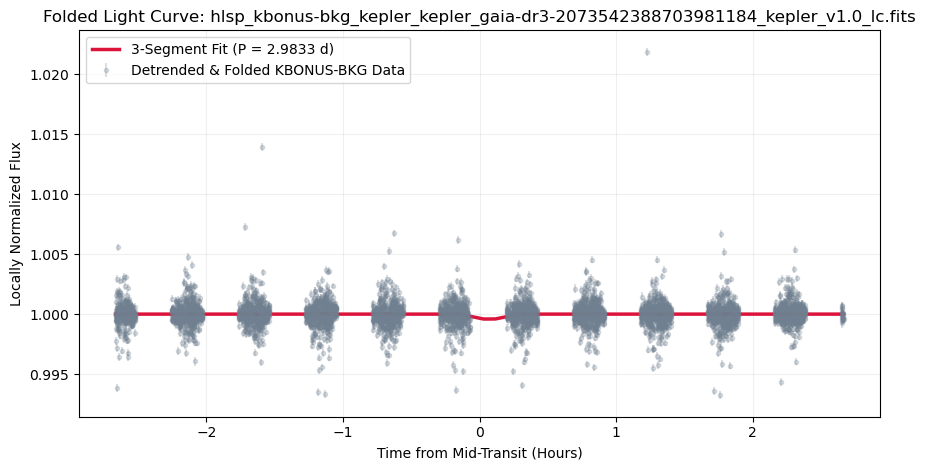

[3/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2073603720839707392_kepler_v1.0_lc.fits...
  Loaded 64811 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.8056 d | Depth: 0.00029



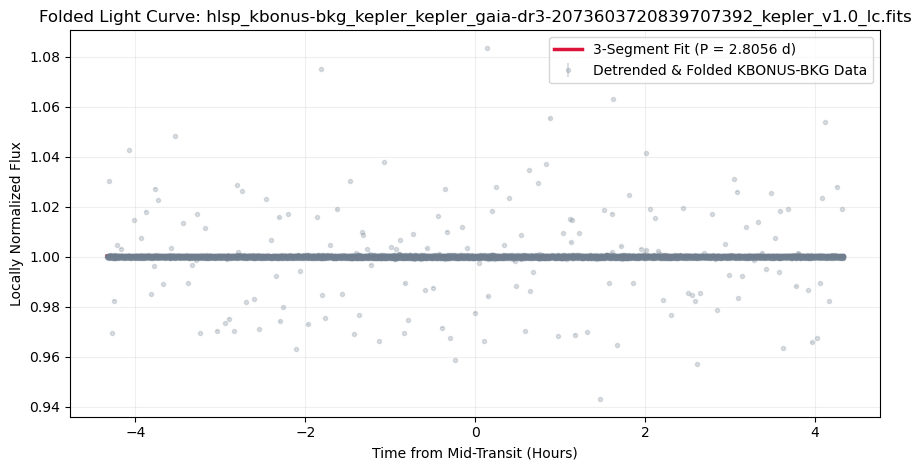

[4/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2073674570599698176_kepler_v1.0_lc.fits...
  Loaded 65279 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9680 d | Depth: 0.00001

[5/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2075345312874959872_kepler_v1.0_lc.fits...
  Loaded 65279 valid cadences spanning 1470.5 days
  Fit complete -> Period: 0.7099 d | Depth: 0.00008

[6/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2076527425323873024_kepler_v1.0_lc.fits...
  Loaded 52294 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7852 d | Depth: 0.00022



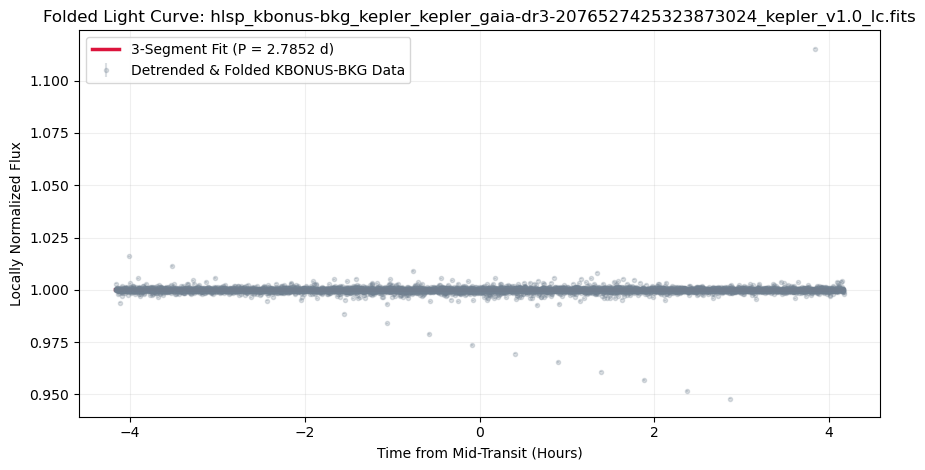

[7/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2076858756282567552_kepler_v1.0_lc.fits...
  Loaded 64810 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.8394 d | Depth: 0.00008

[8/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2076866865177820672_kepler_v1.0_lc.fits...
  Loaded 64810 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.9921 d | Depth: 0.00002

[9/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2077137963511699968_kepler_v1.0_lc.fits...
  Loaded 65276 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9759 d | Depth: 0.00002

[10/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2077170158587049472_kepler_v1.0_lc.fits...
  Loaded 63522 valid cadences spanning 1426.4 days
  Fit complete -> Period: 2.9676 d | Depth: 0.00001

[11/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2077217849902239872_kepler_v1.0_lc.fits...
  Loaded 63522 valid cadences spanning 1426.4 days
  Fit complete -> Period: 

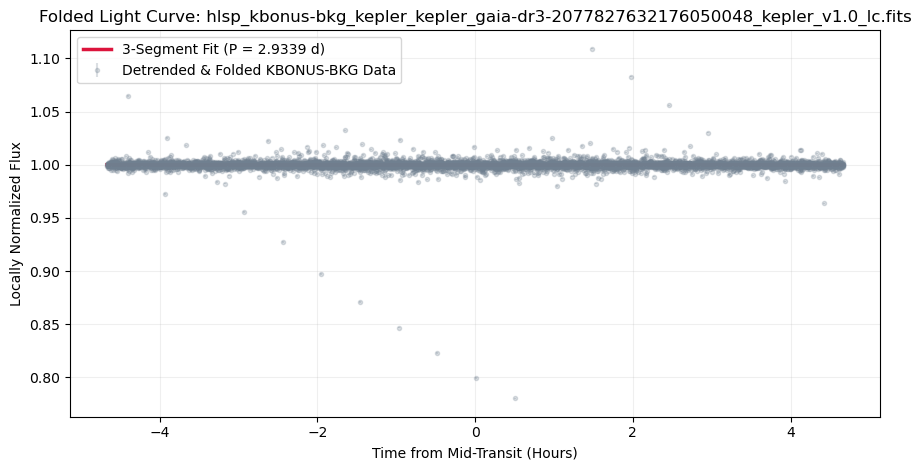

[13/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2077836359553252992_kepler_v1.0_lc.fits...
  Loaded 65275 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7187 d | Depth: 0.00011



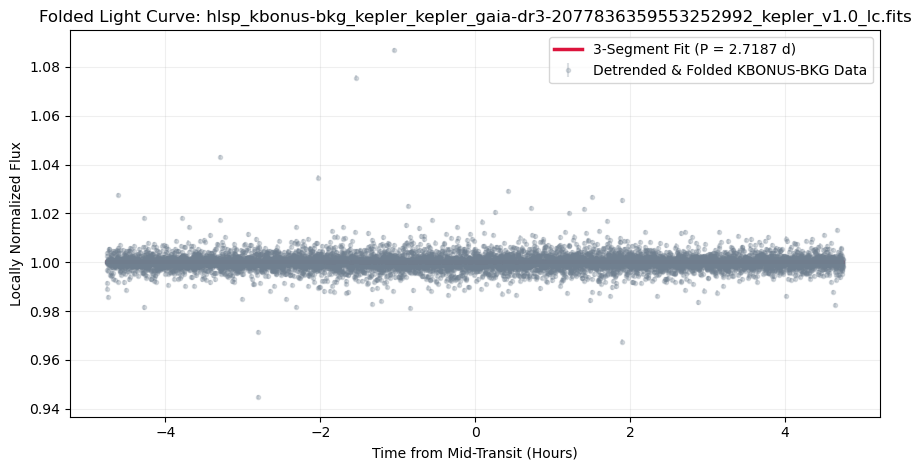

[14/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2078116150903978112_kepler_v1.0_lc.fits...
  Loaded 65276 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7797 d | Depth: 0.00002

[15/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2078276370360834304_kepler_v1.0_lc.fits...
  Loaded 65276 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.8107 d | Depth: 0.00011



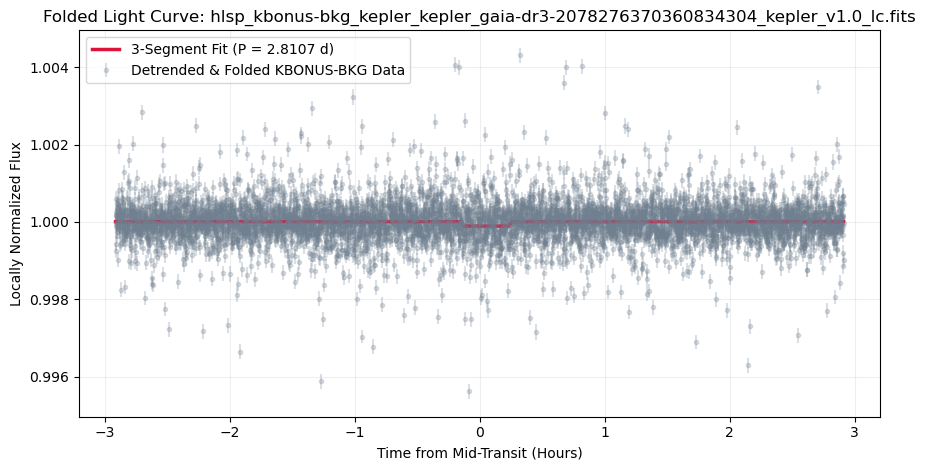

[16/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2078503488237912448_kepler_v1.0_lc.fits...
  Loaded 65278 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.8067 d | Depth: 0.00027



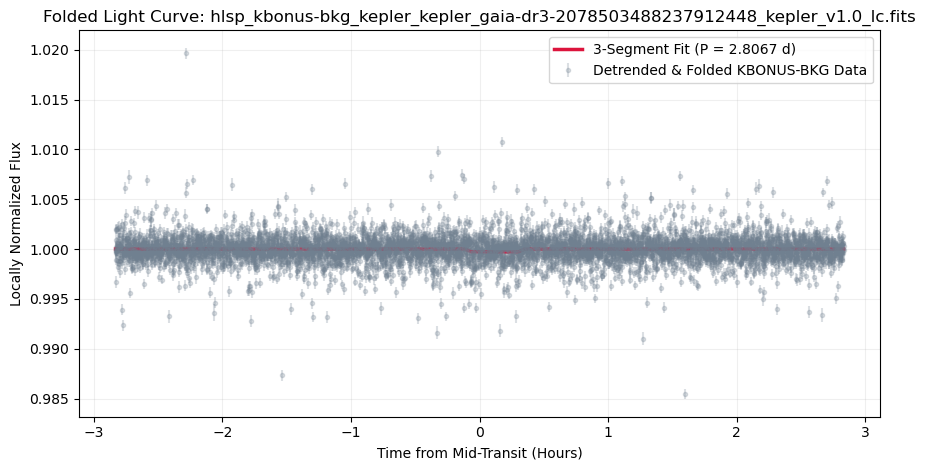

[17/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2078727341923632000_kepler_v1.0_lc.fits...
  Loaded 41008 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.8668 d | Depth: 0.00048



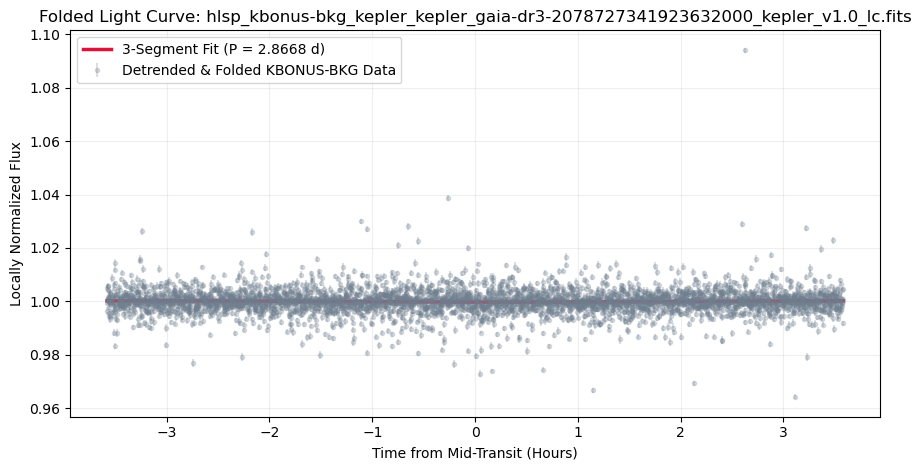

[18/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2079025653175473408_kepler_v1.0_lc.fits...
  Loaded 54557 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.8067 d | Depth: 0.00002

[19/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2079624646495800320_kepler_v1.0_lc.fits...
  Loaded 33771 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.8071 d | Depth: 0.00000

[20/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2080569642379817472_kepler_v1.0_lc.fits...
  Loaded 50117 valid cadences spanning 1421.2 days
  Fit complete -> Period: 0.7870 d | Depth: 0.01375



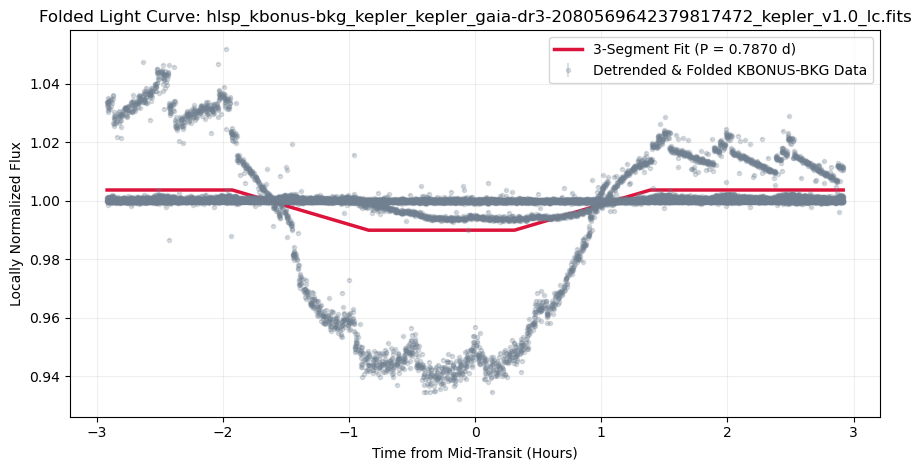

[21/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2080641110632554752_kepler_v1.0_lc.fits...
  Loaded 51741 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.3694 d | Depth: 0.00019



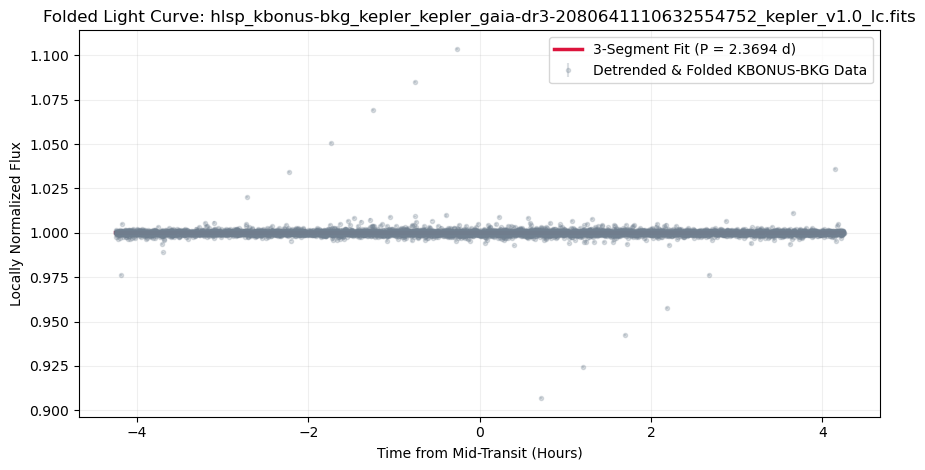

[22/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2086439900592868992_kepler_v1.0_lc.fits...
  Loaded 52214 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.3333 d | Depth: 0.00016



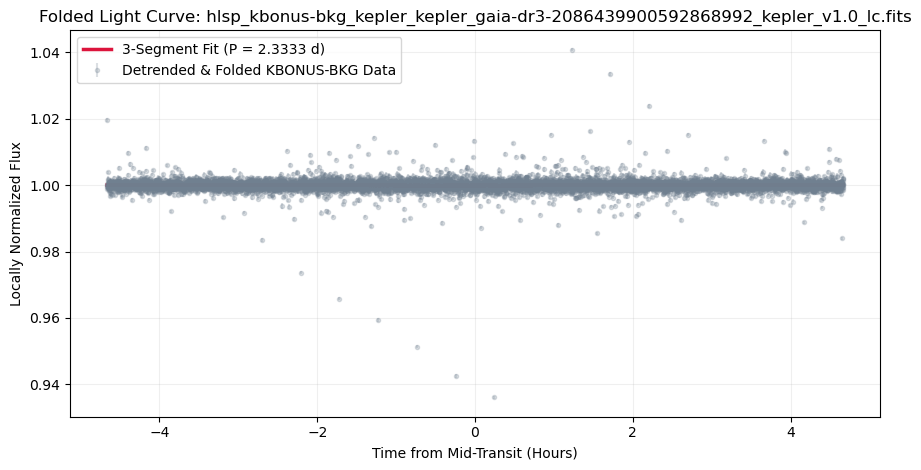

[23/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2086876269277888384_kepler_v1.0_lc.fits...
  Loaded 52212 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.5408 d | Depth: 0.00011



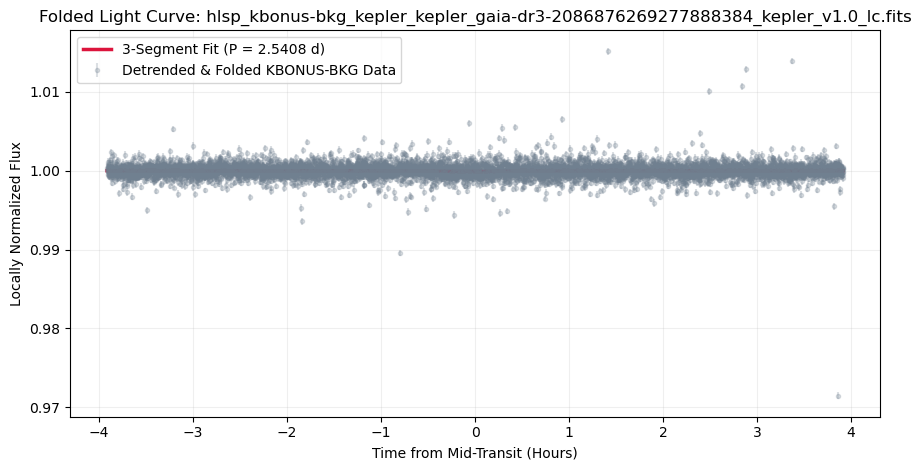

[24/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2101864433829693824_kepler_v1.0_lc.fits...
  Loaded 48558 valid cadences spanning 1388.2 days
  Fit complete -> Period: 2.5510 d | Depth: 0.00009

[25/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2102231773785906304_kepler_v1.0_lc.fits...
  Loaded 54981 valid cadences spanning 1238.6 days
  Fit complete -> Period: 2.5190 d | Depth: 0.00005

[26/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2103527131633898752_kepler_v1.0_lc.fits...
  Loaded 50182 valid cadences spanning 1426.4 days
  Fit complete -> Period: 2.7132 d | Depth: 0.00011



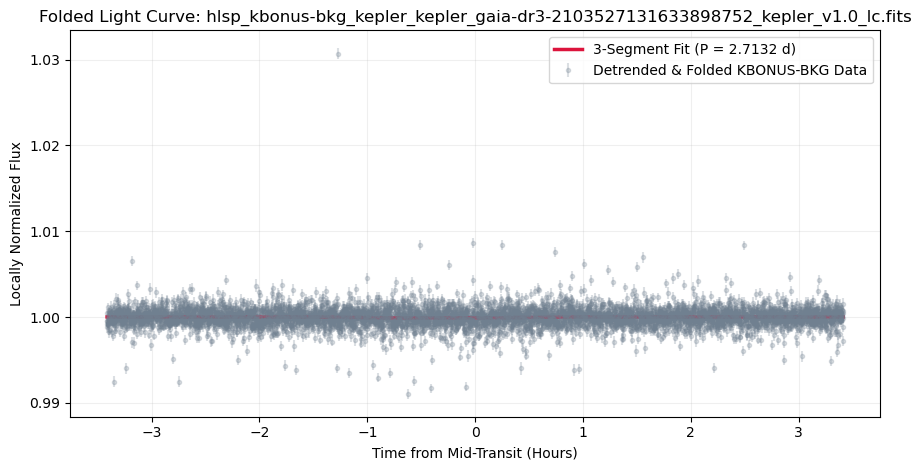

[27/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2104108193458943104_kepler_v1.0_lc.fits...
  Loaded 50651 valid cadences spanning 1437.4 days
  Fit complete -> Period: 2.6856 d | Depth: 0.00004

[28/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2104158186882073856_kepler_v1.0_lc.fits...
  Loaded 50182 valid cadences spanning 1426.4 days
  Fit complete -> Period: 2.4370 d | Depth: 0.00007

[29/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2104247281683574016_kepler_v1.0_lc.fits...
  Loaded 50651 valid cadences spanning 1437.4 days
  Fit complete -> Period: 2.4492 d | Depth: 0.00022



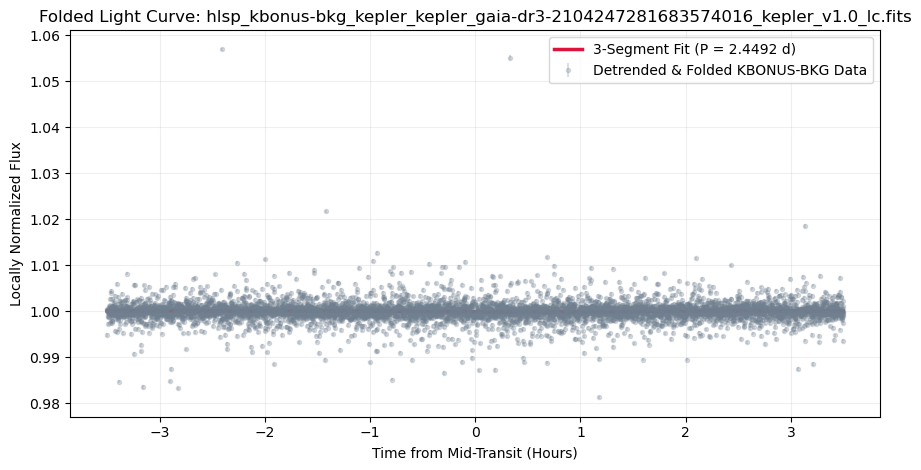

[30/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2105745950391542400_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.9424 d | Depth: 0.00016



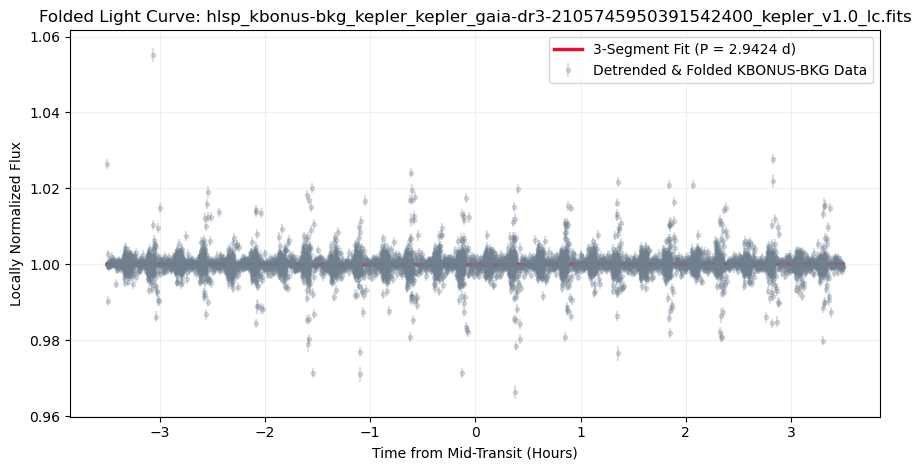

[31/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2106391672952014720_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 0.6545 d | Depth: 0.00044

  Error processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2106391672952014720_kepler_v1.0_lc.fits: 'yerr' must not contain negative values

[32/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2107275920820916608_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.7050 d | Depth: 0.00003

[33/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2107319111009882240_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.7180 d | Depth: 0.00029



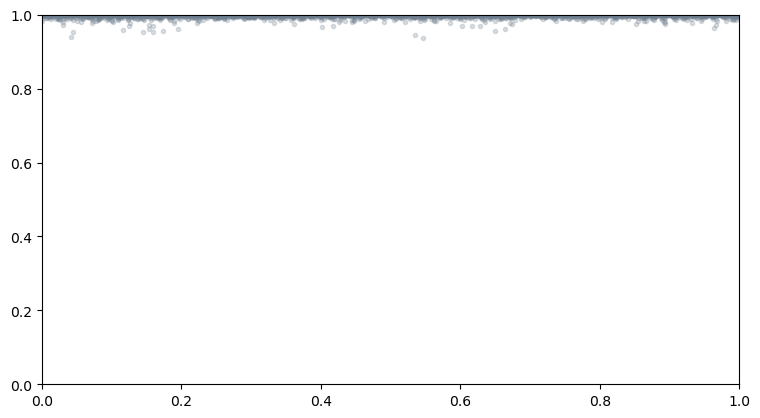

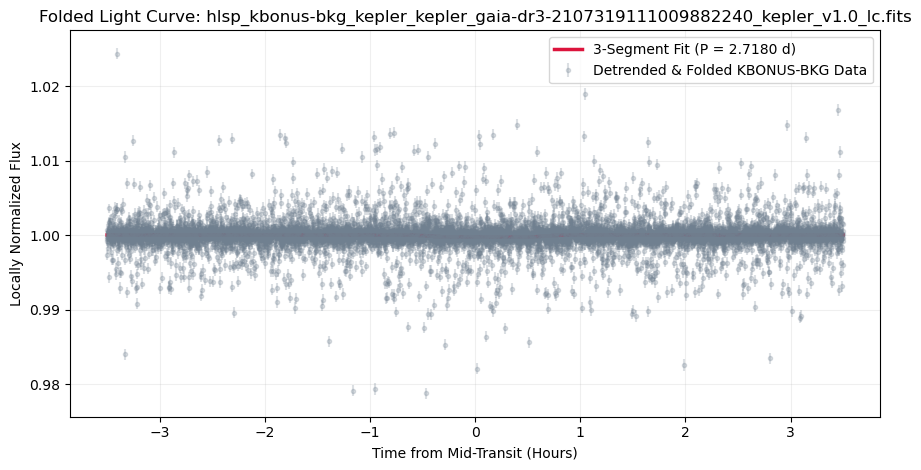

[34/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2116961140793080832_kepler_v1.0_lc.fits...
  Loaded 65275 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.3348 d | Depth: 0.00000

[35/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2117308139787463168_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.7600 d | Depth: 0.00024



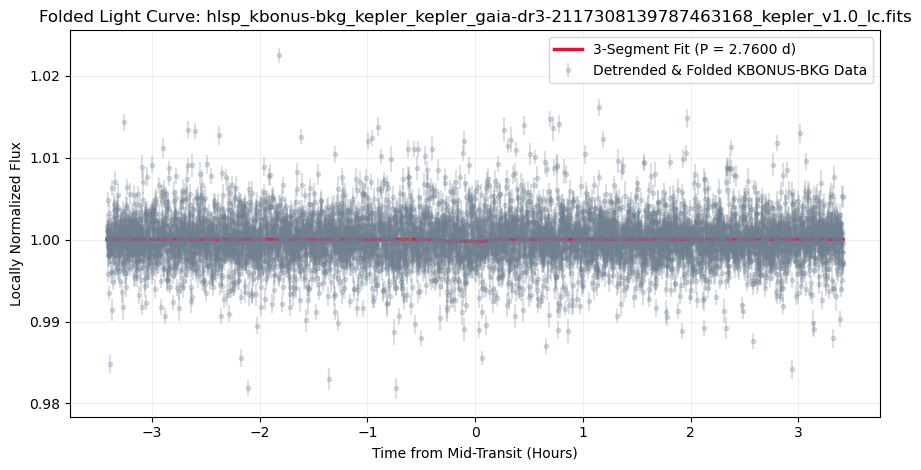

[36/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2119663843451725952_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.8488 d | Depth: 0.00004

[37/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2126346503331610112_kepler_v1.0_lc.fits...
  Loaded 64807 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.5417 d | Depth: 0.00001

[38/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2126650896252682752_kepler_v1.0_lc.fits...
  Loaded 63187 valid cadences spanning 1421.2 days
  Fit complete -> Period: 2.7431 d | Depth: 0.00002

[39/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2126729232154434688_kepler_v1.0_lc.fits...
  Loaded 65279 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7410 d | Depth: 0.00002

[40/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2126952987072805504_kepler_v1.0_lc.fits...
  Loaded 65275 valid cadences spanning 1470.5 days
  Fit complete -> Perio

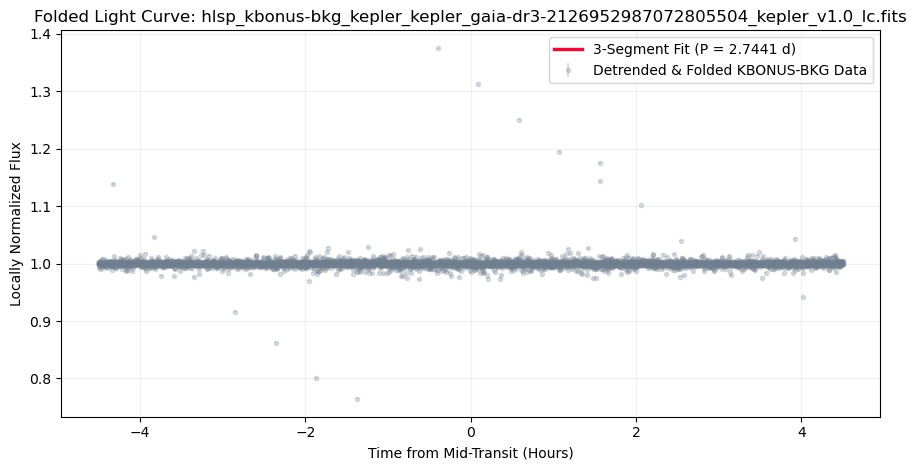

[41/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2127024627126377984_kepler_v1.0_lc.fits...
  Loaded 65280 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.6495 d | Depth: 0.00044



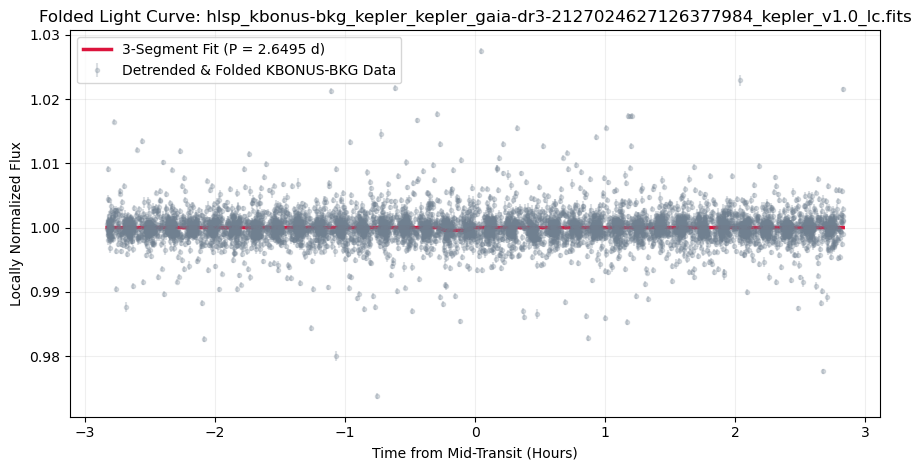

[42/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2128243951162076288_kepler_v1.0_lc.fits...
  Loaded 65279 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.4348 d | Depth: 0.00000

[43/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2129729666244531584_kepler_v1.0_lc.fits...
  Loaded 56717 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.3014 d | Depth: 0.00007

[44/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2130282480076801024_kepler_v1.0_lc.fits...
  Loaded 65274 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9468 d | Depth: 0.00003

[45/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2130851374266398592_kepler_v1.0_lc.fits...
  Loaded 65275 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7403 d | Depth: 0.00015



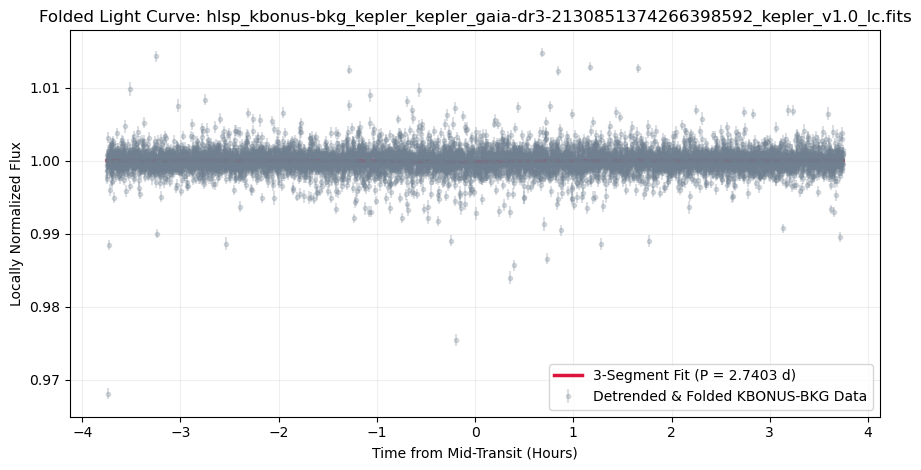

[46/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2130901780003112576_kepler_v1.0_lc.fits...
  Loaded 58059 valid cadences spanning 1470.5 days
  Fit complete -> Period: 1.9954 d | Depth: 0.00000

[47/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2131330726971391360_kepler_v1.0_lc.fits...
  Loaded 65274 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9660 d | Depth: 0.00001

[48/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2132769163063257216_kepler_v1.0_lc.fits...
  Loaded 50972 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.5544 d | Depth: 0.00003

[49/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2132826303309375744_kepler_v1.0_lc.fits...
  Loaded 50972 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9331 d | Depth: 0.00002

[50/125] Processing hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2132997895841149184_kepler_v1.0_lc.fits...
  Loaded 65279 valid cadences spanning 1470.5 days
  Fit complete -> Perio

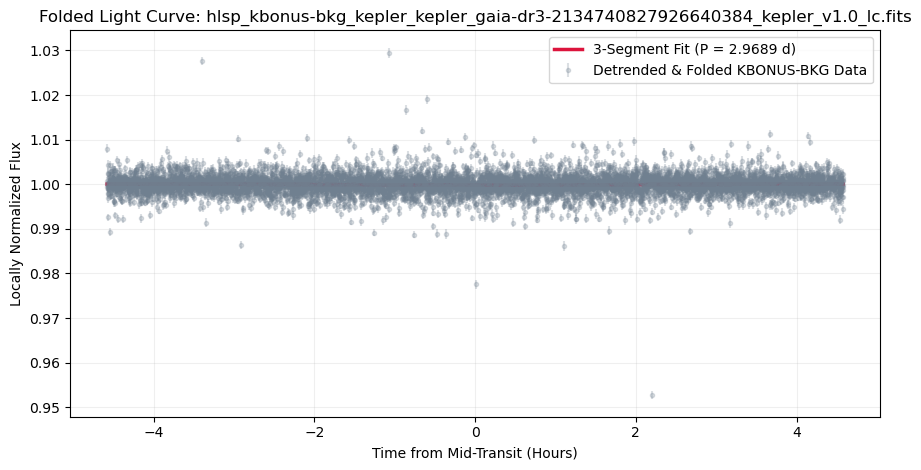

[52/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-002167057_kepler_v1.0_lc.fits...
  Loaded 64808 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.8745 d | Depth: 0.00003

[53/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-002168331_kepler_v1.0_lc.fits...
  Loaded 64808 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.7448 d | Depth: 0.00007

[54/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-002424684_kepler_v1.0_lc.fits...
  Loaded 64807 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.6769 d | Depth: 0.00006

[55/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-002447534_kepler_v1.0_lc.fits...
  Loaded 65277 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9929 d | Depth: 0.00003

[56/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-002852644_kepler_v1.0_lc.fits...
  Loaded 65277 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9664 d | Depth: 0.00002

[57/125] Processing hlsp_kbonus-bkg_kepler_ke

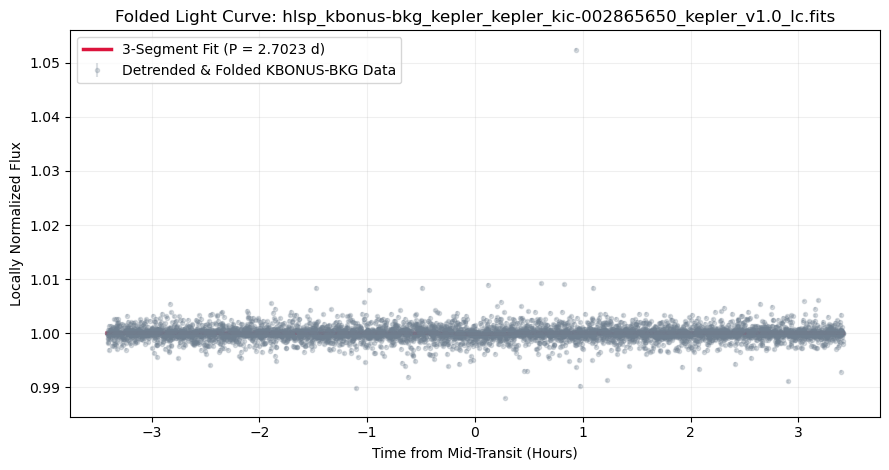

[58/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-003439361_kepler_v1.0_lc.fits...
  Loaded 64807 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.7256 d | Depth: 0.00003

[59/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-003645189_kepler_v1.0_lc.fits...
  Loaded 54980 valid cadences spanning 1238.6 days
  Fit complete -> Period: 2.8060 d | Depth: 0.00002

[60/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-003934452_kepler_v1.0_lc.fits...
  Loaded 65275 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7260 d | Depth: 0.00007

[61/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-003957088_kepler_v1.0_lc.fits...
  Loaded 56437 valid cadences spanning 1470.5 days
  Fit complete -> Period: 0.5398 d | Depth: 0.00005

[62/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-004069478_kepler_v1.0_lc.fits...
  Loaded 47476 valid cadences spanning 1350.6 days
  Fit complete -> Period: 2.8293 d | Depth: 0.00004

[63/125] Processing hlsp_kbonus-bkg_kepler_ke

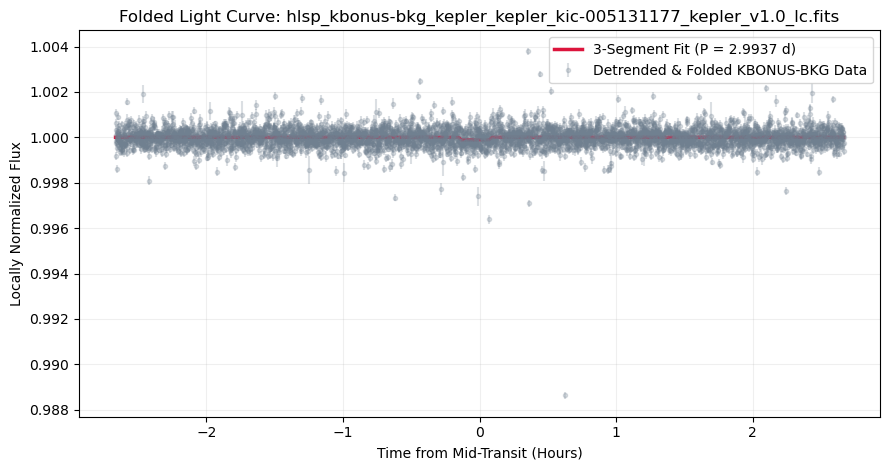

[68/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-005218770_kepler_v1.0_lc.fits...
  Loaded 63525 valid cadences spanning 1426.4 days
  Fit complete -> Period: 2.3994 d | Depth: 0.00002

[69/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-005350364_kepler_v1.0_lc.fits...
  Loaded 64807 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.7170 d | Depth: 0.00008

[70/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-005377383_kepler_v1.0_lc.fits...
  Loaded 51825 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.6028 d | Depth: 0.00004

[71/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-005383000_kepler_v1.0_lc.fits...
  Loaded 65279 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9958 d | Depth: 0.00014



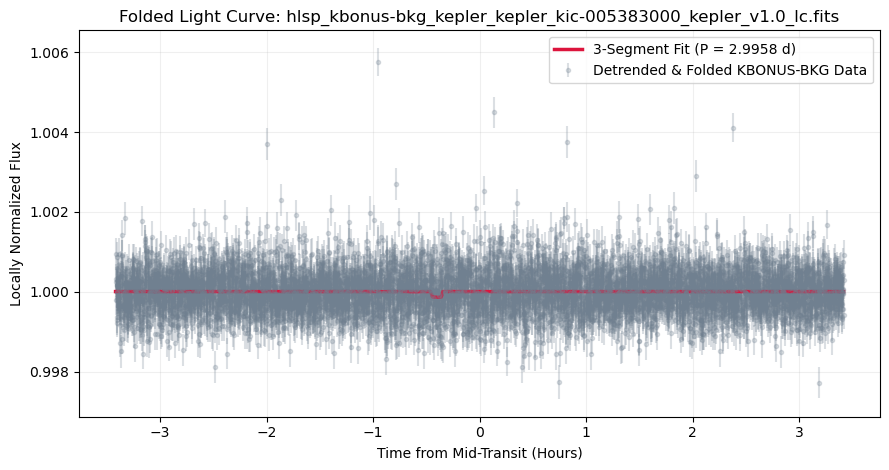

[72/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-005530605_kepler_v1.0_lc.fits...
  Loaded 65276 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.1806 d | Depth: 0.00001

[73/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-005566464_kepler_v1.0_lc.fits...
  Loaded 64811 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.8222 d | Depth: 0.00008

[74/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-006036179_kepler_v1.0_lc.fits...
  Loaded 50872 valid cadences spanning 1147.5 days
  Fit complete -> Period: 2.9643 d | Depth: 0.00002

[75/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-006374056_kepler_v1.0_lc.fits...
  Loaded 64806 valid cadences spanning 1459.5 days
  Fit complete -> Period: 1.0578 d | Depth: 0.00465



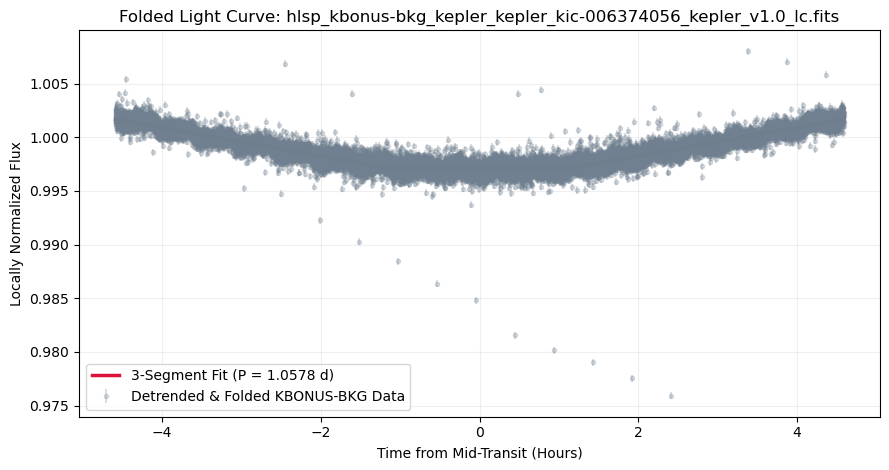

[76/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-006763897_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 1.9555 d | Depth: 0.00004

[77/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-006785077_kepler_v1.0_lc.fits...
  Loaded 65275 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7043 d | Depth: 0.00009

[78/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-006852621_kepler_v1.0_lc.fits...
  Loaded 65275 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7928 d | Depth: 0.00002

[79/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-006950888_kepler_v1.0_lc.fits...
  Loaded 64806 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.2345 d | Depth: 0.00004

[80/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-007032734_kepler_v1.0_lc.fits...
  Loaded 64807 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.4966 d | Depth: 0.00002

[81/125] Processing hlsp_kbonus-bkg_kepler_ke

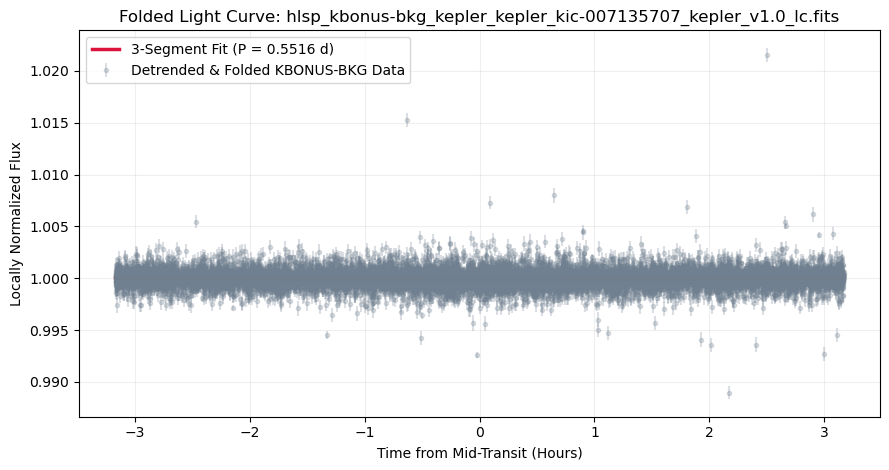

[82/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-007670498_kepler_v1.0_lc.fits...
  Loaded 54976 valid cadences spanning 1238.6 days
  Fit complete -> Period: 0.5770 d | Depth: 0.00012



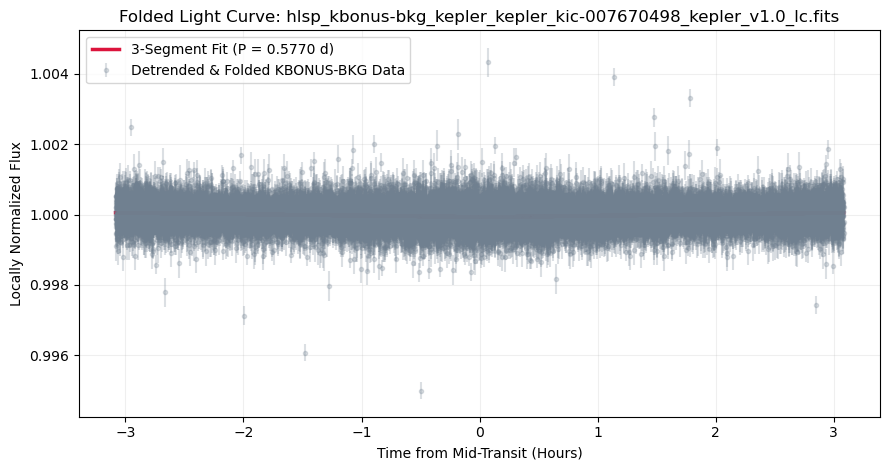

[83/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-007738913_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 0.6370 d | Depth: 0.00010

[84/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-007770251_kepler_v1.0_lc.fits...
  Loaded 65278 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.8282 d | Depth: 0.00005

[85/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-007910100_kepler_v1.0_lc.fits...
  Loaded 64809 valid cadences spanning 1459.5 days
  Fit complete -> Period: 0.7274 d | Depth: 0.00007

[86/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-007944146_kepler_v1.0_lc.fits...
  Loaded 45986 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.6050 d | Depth: 0.00005

[87/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-007971226_kepler_v1.0_lc.fits...
  Loaded 64807 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.9664 d | Depth: 0.00005

[88/125] Processing hlsp_kbonus-bkg_kepler_ke

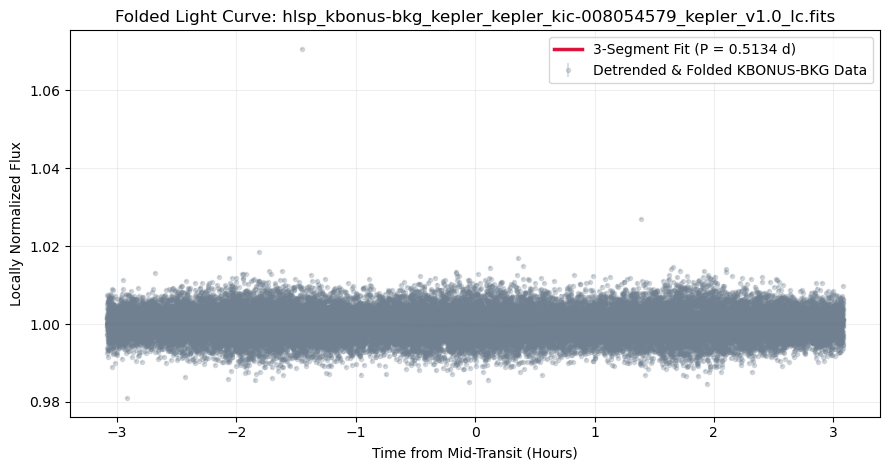

[91/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-008183703_kepler_v1.0_lc.fits...
  Loaded 47606 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.8104 d | Depth: 0.00003

[92/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-008285648_kepler_v1.0_lc.fits...
  Loaded 48558 valid cadences spanning 1388.2 days
  Fit complete -> Period: 2.1143 d | Depth: 0.00002

[93/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-008324683_kepler_v1.0_lc.fits...
  Loaded 65279 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.5362 d | Depth: 0.00011



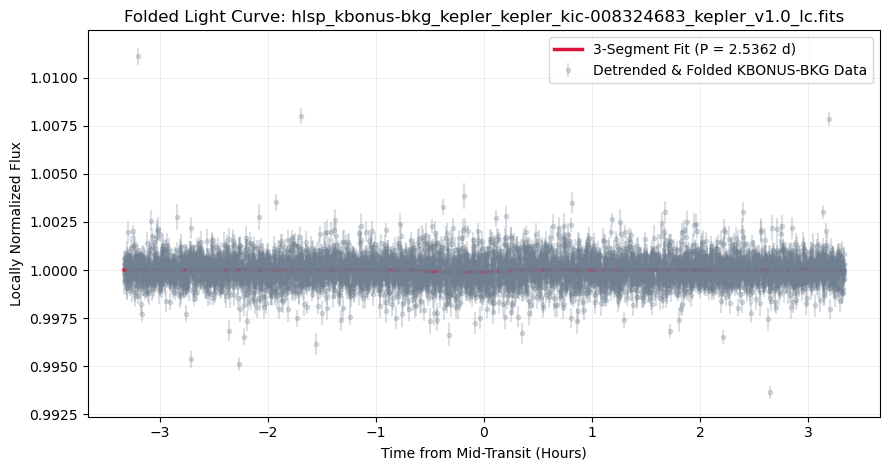

[94/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-008364753_kepler_v1.0_lc.fits...
  Loaded 48222 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.9664 d | Depth: 0.00005

[95/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-008388905_kepler_v1.0_lc.fits...
  Loaded 56350 valid cadences spanning 1350.6 days
  Fit complete -> Period: 2.5357 d | Depth: 0.00004

[96/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-008494837_kepler_v1.0_lc.fits...
  Loaded 65276 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.6857 d | Depth: 0.00002

[97/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-008540382_kepler_v1.0_lc.fits...
  Loaded 56565 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.8356 d | Depth: 0.00004

[98/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-008590440_kepler_v1.0_lc.fits...
  Loaded 64812 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.5190 d | Depth: 0.00007

[99/125] Processing hlsp_kbonus-bkg_kepler_ke

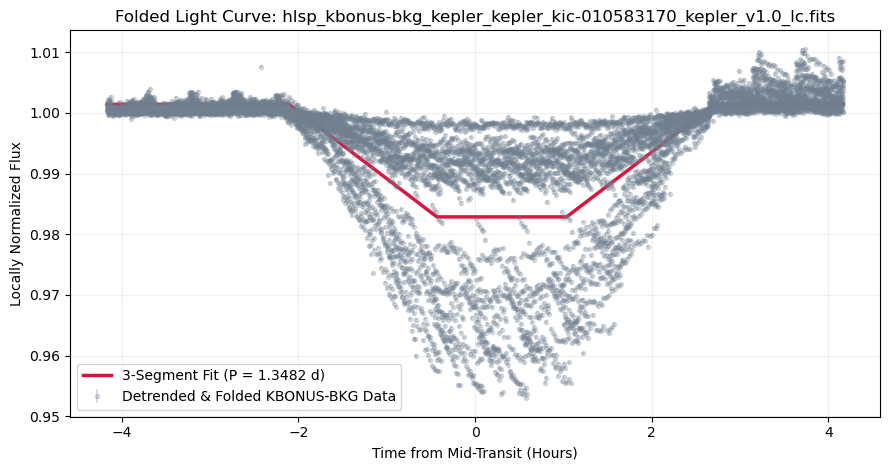

[118/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-010614779_kepler_v1.0_lc.fits...
  Loaded 52210 valid cadences spanning 1470.5 days
  Fit complete -> Period: 2.7050 d | Depth: 0.00005

[119/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-010716790_kepler_v1.0_lc.fits...
  Loaded 50504 valid cadences spanning 1459.5 days
  Fit complete -> Period: 2.6280 d | Depth: 0.00002

[120/125] Processing hlsp_kbonus-bkg_kepler_kepler_kic-010727532_kepler_v1.0_lc.fits...
  Loaded 64805 valid cadences spanning 1459.5 days
  Fit complete -> Period: 0.6157 d | Depth: 0.00024



In [ ]:
if __name__ == "__main__":
    directory = Path("../kepler_bonus/lightcurves")
    
    # Sort alphabetically/numerically by filename and only grab .fits files
    fits_files = sorted(directory.glob("*.fits"))
    
    print(f"Found {len(fits_files)} FITS files to process.\n")

    for i, item in enumerate(fits_files, start=1):
        print(f"[{i}/{len(fits_files)}] Processing {item.name}...")
        
        try:
            # Load KBONUS-BKG stitched light curve
            time, flux, flux_err = read_fits_fast(item)
            print(f"  Loaded {len(time)} valid cadences spanning {time[-1] - time[0]:.1f} days")
        
            # Run inline FFT + 3-segment fit
            fft_period, fft_t0, dur_est = find_period_and_t0_fft(time, flux)
            
            # 5-hour local linear detrending (2.5 hr pre + 2.5 hr post) & phase-folding
            phase_days, flux_folded, err_folded = detrend_and_fold(
                time, flux, flux_err, period=fft_period, t0=fft_t0,
                transit_duration_est=dur_est, window_hours=5.0
            )
            
            # Constrained three-segment symmetric fit (>= 5 min flat bottom)
            est_depth = max(0.001, 1.0 - np.percentile(flux_folded, 5))
            p0 = [1.0, est_depth, 0.0, dur_est * 0.6, dur_est * 0.2]
            res = fit_transit_profile(phase_days, flux_folded, err_folded, p0)
            baseline, depth, t_mid, dur_flat, dur_slope = res.x
            
            print(f"  Fit complete -> Period: {fft_period:.4f} d | Depth: {depth:.5f}\n")

            # Plot the locally detrended, folded light curve and 3-segment fit
            if 0.0001 <= depth <= 0.02:
                plt.figure(figsize=(9, 4.8))
                plt.errorbar(
                    phase_days * 24.0, flux_folded, yerr=err_folded,
                    fmt=".", color="slategray", alpha=0.25, label="Detrended & Folded KBONUS-BKG Data"
                )
                
                t_grid = np.linspace(phase_days.min(), phase_days.max(), 1000)
                plt.plot(
                    t_grid * 24.0, three_segment_model(t_grid, *res.x),
                    color="crimson", linewidth=2.5, label=f"3-Segment Fit (P = {fft_period:.4f} d)"
                )
                
                plt.xlabel("Time from Mid-Transit (Hours)")
                plt.ylabel("Locally Normalized Flux")
                plt.title(f"Folded Light Curve: {item.name}")
                plt.legend()
                plt.grid(alpha=0.2)
                plt.tight_layout()
                plt.show()
                
        except Exception as e:
            print(f"  Error processing {item.name}: {e}\n")

In [ ]:
# check if there's any sort of deviation for the trapezoid -> if there is, add it to an array that I can then print out
        # this should reduce the amount that I have to look at by eye enough that I can check it all individually